# SMS Spam Classification using Machine Learning

## Project Overview

This project builds a machine learning model to classify SMS messages as spam or ham (legitimate messages).

The main objective is to detect spam messages while minimizing false positives, since incorrectly classifying legitimate messages as spam can cause important messages to be missed.

### Technologies
- Python
- Pandas & NumPy
- Matplotlib
- Scikit-learn
- TF-IDF
- Logistic Regression
- Multinomial Naive Bayes

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/spam.csv",encoding="latin-1")

df = df.rename(columns={"v1":"label","v2":"message"})

df.head()

,label,message,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## 1. Data Loading and Cleaning

The dataset contains labeled SMS messages categorized as `spam` or `ham`.

### Preprocessing Steps
- Loaded the dataset using Pandas.
- Removed unnecessary columns.
- Renamed columns for readability.
- Checked for missing values.
- Removed 403 duplicate records.
- Analyzed the class distribution.

Duplicate messages were removed to reduce redundant training samples and prevent identical messages from appearing in both training and test sets.

In [20]:
df = df.drop(columns=["Unnamed: 2","Unnamed: 3","Unnamed: 4"],errors="ignore")

round(df["label"].value_counts(normalize=True) * 100,2)

df.isnull().sum()

df = df.drop_duplicates()

df.duplicated(subset="message").sum()

np.int64(0)

## 2. Exploratory Data Analysis (EDA)

Explored the dataset to identify differences between spam and legitimate messages.

### Feature Exploration
- Calculated character counts for each message.
- Calculated word counts for each message.
- Compared average message lengths across classes.
- Visualized character distributions using histograms.

In [21]:
def char_count(s):
  return len(str(s))

def word_count(s):
  return len(str(s).split())

df["num_of_char"] = df["message"].apply(char_count)
df["num_of_word"] = df["message"].apply(word_count)

df.groupby("label")[["num_of_char","num_of_word"]].agg(["min","max","mean","median"]).round(2)

num_of_char                     num_of_word                   
              min  max    mean median         min  max   mean median
label                                                               
ham             2  910   70.46   52.0           1  171  14.13   11.0
spam           13  224  137.89  149.0           2   35  23.68   25.0

### Key Observation
Spam messages tend to contain more characters than legitimate messages.

However, message length alone is insufficient for reliable classification because the distributions overlap.

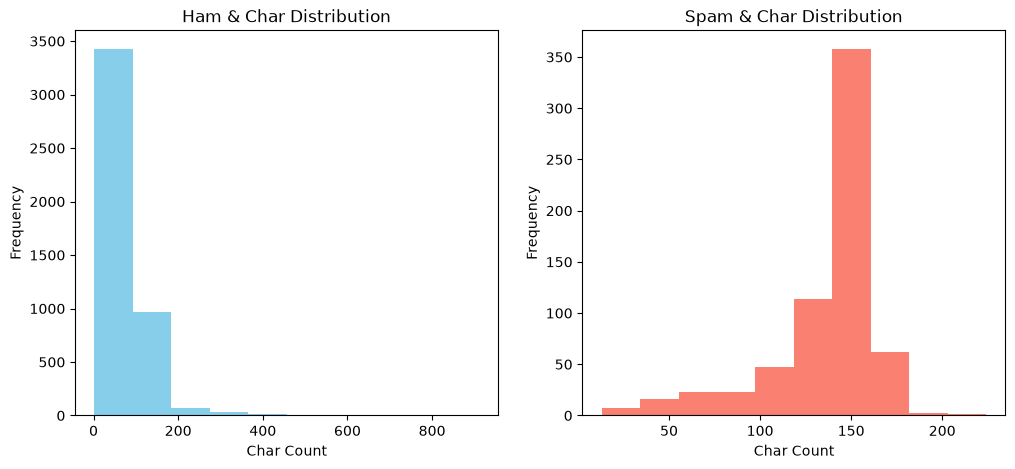

In [22]:
fig , axes = plt.subplots(1,2,figsize = (12,5))

axes[0].hist(df[df["label"] == "ham"]["num_of_char"],color="skyblue")
axes[0].set_title("Ham & Char Distribution")
axes[0].set_xlabel("Char Count")
axes[0].set_ylabel("Frequency")

axes[1].hist(df[df["label"] == "spam"]["num_of_char"],color="salmon")
axes[1].set_title("Spam & Char Distribution")
axes[1].set_xlabel("Char Count")
axes[1].set_ylabel("Frequency")

plt.show()

## 3. Train/Test Split

The dataset was divided into:

- Training set: 80%
- Test set: 20%

Stratified sampling was used to preserve the spam-to-ham ratio in both datasets.

A fixed random state ensures reproducibility.

In [23]:
from sklearn.model_selection import train_test_split

X = df["message"]
y =  df["label"]

X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y
)

print(X_train.shape)
print(X_test.shape)

(4135,)
(1034,)


## 4. TF-IDF Vectorization

Machine learning models cannot directly process raw text, so messages were converted into numerical feature vectors using TF-IDF (Term Frequency–Inverse Document Frequency).

TF-IDF assigns weights based on how frequently a term appears in a message and how rare it is across the training corpus.

### Implementation
- Applied `fit_transform()` to training data.
- Applied `transform()` to test data.
- Learned the vocabulary and IDF statistics exclusively from training data to prevent data leakage.

The initial unigram representation generated 7,591 features.

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

vectorizer.get_feature_names_out()

(4135, 7591)
(1034, 7591)


array(['00', '000', '000pes', ..., 'ûïharry', 'ûò', 'ûówell'],
      shape=(7591,), dtype=object)

## 5. Model Training

Two classification algorithms were trained:

### Multinomial Naive Bayes
A probabilistic classifier commonly used for text classification.

### Logistic Regression
A linear classification algorithm that estimates class probabilities using the sigmoid function.

Both models were trained on the same TF-IDF features to enable a consistent comparison.

In [25]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf,y_train)

y_pred = nb_model.predict(X_test_tfidf)

cm = confusion_matrix(y_test,y_pred)

accuracy = accuracy_score(y_test,y_pred)

precision = precision_score(y_test,y_pred,pos_label="spam")

recall = recall_score(y_test,y_pred,pos_label="spam")

print("Confusion Matrix:\n",cm)
print(f"Accuracy Score: {accuracy:.1%}")
print(f"Precision: {precision:.1%}")
print(f"Recall: {recall:.1%}")

Confusion Matrix:
 [[903   0]
 [ 50  81]]
Accuracy Score: 95.2%
Precision: 100.0%
Recall: 61.8%


In [26]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf,y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)

cm = confusion_matrix(y_test,y_pred_lr)

accuracy = accuracy_score(y_test,y_pred_lr)

precision = precision_score(y_test,y_pred_lr,pos_label="spam")

recall = recall_score(y_test,y_pred_lr,pos_label="spam")

print("Confusion Matrix:\n",cm)
print(f"Accuracy Score: {accuracy:.1%}")
print(f"Precision: {precision:.1%}")
print(f"Recall: {recall:.1%}")

Confusion Matrix:
 [[902   1]
 [ 33  98]]
Accuracy Score: 96.7%
Precision: 99.0%
Recall: 74.8%


## 6. Model Evaluation

Model performance was evaluated using:

- Accuracy
- Precision
- Recall
- Confusion Matrix

Spam was defined as the positive class.

### Baseline Results

| Metric | Naive Bayes | Logistic Regression |
|---|---:|---:|
| Accuracy | 95.2% | 96.7% |
| Spam Precision | 100.0% | 99.0% |
| Spam Recall | 61.8% | 74.8% |
| False Positives | 0 | 1 |
| False Negatives | 50 | 33 |

Logistic Regression detected more spam messages while maintaining high precision.

In [27]:
results = pd.DataFrame({
    "Message": X_test,
    "Actual": y_test,
    "Predicted" : y_pred_lr,
})

wrong_pred = results[(results["Actual"] == "spam") & (results["Predicted"] == "ham")]

print("FN:" ,len(wrong_pred))
print(wrong_pred.Message[:10])

FN: 33
5537    Want explicit SEX in 30 secs? Ring 02073162414...
528     You will recieve your tone within the next 24h...
2828    Send a logo 2 ur lover - 2 names joined by a h...
491     Congrats! 1 year special cinema pass for 2 is ...
1662    Hi if ur lookin 4 saucy daytime fun wiv busty ...
5098    TheMob>Hit the link to get a premium Pink Pant...
1448    As a registered optin subscriber ur draw 4 å£1...
5540    ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE ...
4671    Customer service announcement. We recently tri...
1698    Free msg. Sorry, a service you ordered from 81...
Name: Message, dtype: str


In [28]:
y_prob = lr_model.predict_proba(X_test_tfidf)[:,1] ## [:,1] --> Spam class

percentage = np.round(y_prob * 100,2)

results = pd.DataFrame({
    "Actual" : y_test,
    "Predicted" : y_pred_lr,
    "Spam Probability": percentage
})

fn = results[(results["Actual"] == "spam") & (results["Predicted"] == "ham")]

print(fn[:10])

     Actual Predicted  Spam Probability
5537   spam       ham             14.45
528    spam       ham             24.16
2828   spam       ham             36.73
491    spam       ham             37.89
1662   spam       ham             26.34
5098   spam       ham             42.02
1448   spam       ham             33.47
5540   spam       ham              9.86
4671   spam       ham             40.94
1698   spam       ham             42.09


## 7. Decision Threshold Analysis

The classification threshold was reduced from 0.5 to 0.3 to investigate the trade-off between precision and recall.

| Metric | Threshold 0.5 | Threshold 0.3 |
|---|---:|---:|
| Precision | 99.0% | 94.1% |
| Recall | 74.8% | 84.7% |
| False Positives | 1 | 7 |
| False Negatives | 33 | 20 |

Lowering the threshold increased spam detection but also increased the number of legitimate messages incorrectly classified as spam.

The threshold was explored experimentally rather than selected through a dedicated validation set.

In [29]:
threshold = 0.3

y_prob_new = np.where(y_prob >= threshold,"spam","ham")

print("Confusion Matrix:")
print(confusion_matrix(y_test,y_prob_new))

precision = precision_score(y_test, y_prob_new, pos_label="spam")

recall = recall_score(y_test, y_prob_new, pos_label="spam")

print(f"Precision:{precision:.1%}")
print(f"Recall:{recall:.1%}")

Confusion Matrix:
[[896   7]
 [ 20 111]]
Precision:94.1%
Recall:84.7%


## 8. Error Analysis

False negative predictions were analyzed to understand why spam messages were missed.

### Observations
Several misclassified messages contained:
- Misspelled words
- Abbreviations
- Informal language
- Unusual character sequences
- Promotional phrases

These observations motivated experiments with word and character n-grams.

The identified patterns are hypotheses rather than confirmed causes of prediction errors.

In [30]:
vectorizer_word = TfidfVectorizer(analyzer="word",ngram_range=(1,2))

X_train_tfidf_word = vectorizer_word.fit_transform(X_train)
X_test_tfidf_word = vectorizer_word.transform(X_test)

vectorizer_char = TfidfVectorizer(analyzer="char",ngram_range=(3,5))

X_train_tfidf_char = vectorizer_char.fit_transform(X_train)
X_test_tfidf_char = vectorizer_char.transform(X_test)

print(X_train_tfidf_word.shape)
print(X_test_tfidf_word.shape)
print(X_train_tfidf_char.shape)
print(X_test_tfidf_char.shape)

(4135, 42219)
(1034, 42219)
(4135, 131764)
(1034, 131764)


## 9. N-gram Experiments

Three TF-IDF representations were compared using Logistic Regression:

1. Unigrams
2. Word n-grams (1,2)
3. Character n-grams (3,5)

### Results

| Representation | Features | Precision | Recall |
|---|---:|---:|---:|
| Unigrams | 7,591 | 99.0% | 74.8% |
| Word n-grams | 42,219 | 98.9% | 65.6% |
| Character n-grams | 131,764 | 98.9% | 70.2% |

Increasing the number of features did not improve performance in these experiments.

The unigram representation achieved the highest recall at the default decision threshold.

In [31]:
word_model = LogisticRegression(max_iter=1000)
char_model = LogisticRegression(max_iter=1000)

word_model.fit(X_train_tfidf_word,y_train)
char_model.fit(X_train_tfidf_char,y_train)

y_pred_word = word_model.predict(X_test_tfidf_word)
y_pred_char = char_model.predict(X_test_tfidf_char)

print(y_pred_word)
print(y_pred_char)

['ham' 'ham' 'ham' ... 'spam' 'ham' 'ham']
['ham' 'ham' 'ham' ... 'spam' 'ham' 'ham']


In [32]:
cm_word = confusion_matrix(y_test,y_pred_word)
cm_char = confusion_matrix(y_test,y_pred_char)

precision_word = precision_score(y_test,y_pred_word,pos_label="spam")
precision_char = precision_score(y_test,y_pred_char,pos_label="spam")

recall_word = recall_score(y_test,y_pred_word,pos_label="spam")
recall_char = recall_score(y_test,y_pred_char,pos_label="spam")

print("Confusion Matrix Word-Gram:\n",cm_word)
print(f"Precision Word-Gram: {precision_word:.1%}")
print(f"Recall Word-Gram: {recall_word:.1%}")

print("\n")

print("Confusion Matrix Char-Gram:\n",cm_char)
print(f"Precision Char-Gram: {precision_char:.1%}")
print(f"Recall Char-Gram: {recall_char:.1%}")

Confusion Matrix Word-Gram:
 [[902   1]
 [ 45  86]]
Precision Word-Gram: 98.9%
Recall Word-Gram: 65.6%


Confusion Matrix Char-Gram:
 [[902   1]
 [ 39  92]]
Precision Char-Gram: 98.9%
Recall Char-Gram: 70.2%


## 10. Machine Learning Pipeline

A Scikit-learn Pipeline was created to combine TF-IDF vectorization and Logistic Regression.

### Pipeline Steps
1. Convert raw text into TF-IDF features.
2. Generate predictions using Logistic Regression.

### Benefits
- Simplifies preprocessing and prediction.
- Ensures consistent transformations.
- Reduces the risk of data leakage during cross-validation.
- Makes the model easier to save and deploy.

The Pipeline reproduced the original Logistic Regression results:
- Precision: 99.0%
- Recall: 74.8%

In [33]:
from sklearn.pipeline import Pipeline

spam_pipeline = Pipeline([
    ("tfidf",TfidfVectorizer()),
    ("classifier",LogisticRegression(max_iter=1000))
])

spam_pipeline.fit(X_train,y_train)

y_predict_pipe = spam_pipeline.predict(X_test)

print(y_predict_pipe)

['ham' 'ham' 'ham' ... 'spam' 'ham' 'ham']


In [34]:
cm_pipe = confusion_matrix(y_test,y_predict_pipe)

precision_pipe = precision_score(y_test,y_predict_pipe,pos_label="spam")

recall_pipe = recall_score(y_test,y_predict_pipe,pos_label="spam")

print("Confusion Matrix Pipeline:\n",cm_pipe)
print(f"Precision Pipeline: {precision_pipe:.1%}")
print(f"Recall Pipeline: {recall_pipe:.1%}")

spam_pipeline.predict(
    [ "Congratulations! You've won a $1,000 gift card! Click the link below to claim your prize before it expires.",
      "URGENT! Your bank account has been suspended. Verify your personal information immediately to restore access.",
      "Hey John, just wanted to remind you about our meeting tomorrow at 10 AM. Let me know if you need to reschedule.",
      "Hi Sarah, I've attached the project report you requested. Please review it when you have time and share your feedback."
     ])

Confusion Matrix Pipeline:
 [[902   1]
 [ 33  98]]
Precision Pipeline: 99.0%
Recall Pipeline: 74.8%


array(['spam', 'spam', 'ham', 'ham'], dtype=object)

## 11. Limitations and Future Improvements

### Limitations
- The model was trained on SMS messages rather than emails.
- The dataset is relatively small.
- Word-based TF-IDF does not fully capture semantic context.
- The same test set was used during multiple experiments, so reported results should be considered exploratory rather than an unbiased final estimate.

### Future Improvements
- Use a dedicated validation set for model selection.
- Optimize decision thresholds.
- Experiment with regularization and feature extraction.
- Evaluate on unseen messages.
- Deploy the trained model using FastAPI.